# Medical Prescription Handwriting DCGAN Training Lab (Google Colab)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Shruti-25092005/AI-Medical-Prescription-Analyzer/blob/main/notebooks/GAN_Training.ipynb)

This interactive notebook trains an advanced **Deep Convolutional GAN (DCGAN)** on genuine doctor-written medical prescription word crops from the **RxHandBD-ML** benchmark dataset.

### Training Highlights:
- **Dynamic Resolution:** Supports $64\times 64$ baseline and $128\times 128$ high-definition cursive script.
- **Safe Stroke Synthesis:** Strictly synthesizes isolated non-semantic handwriting word strokes and abstract ligatures. **Completely medication-free, zero-PHI.**
- **Robust Colab Auto-Setup:** Automatically clones the GitHub repository and resolves dataset paths regardless of VM runtime environment.


In [1]:
# Cell 1: Environment Setup, Auto-Cloning & Hardware Acceleration Check
import os
import sys
import subprocess
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

# Detect environment
IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')

# Candidate paths where repository or dataset may reside
candidates = [
    Path.cwd(),
    Path.cwd().resolve().parent,
    Path('/content/AI-Medical-Prescription-Analyzer'),
    Path('/content/AI_Prescription_Analyzer'),
    Path('/content'),
    Path('/content/drive/MyDrive/AI-Medical-Prescription-Analyzer'),
    Path('/content/drive/MyDrive/AI_Prescription_Analyzer'),
]

REPO_ROOT = None
for cand in candidates:
    if (cand / 'dataset' / 'RxHandBD-ML' / 'RxHandBD-ML' / 'Train_Label.csv').is_file() or (cand / 'models' / 'handwriting_gan.py').is_file():
        REPO_ROOT = cand
        break

# If running in Google Colab and repo not yet cloned, automatically clone it
if REPO_ROOT is None and IN_COLAB:
    print("Repository not found in /content. Automatically cloning from GitHub...")
    clone_url = "https://github.com/Shruti-25092005/AI-Medical-Prescription-Analyzer.git"
    target_dir = Path("/content/AI_Prescription_Analyzer")
    subprocess.run(["git", "clone", clone_url, str(target_dir)], check=True)
    REPO_ROOT = target_dir

if REPO_ROOT is None:
    REPO_ROOT = Path('.').resolve()

REPO_ROOT = REPO_ROOT.resolve()
print(f"Repository Root verified: {REPO_ROOT}")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Optional Google Drive mount (non-blocking)
if IN_COLAB:
    try:
        from google.colab import drive
        if not os.path.exists('/content/drive/MyDrive'):
            print("Mounting Google Drive (optional, for persistent storage)...\nClick Cancel if you prefer direct session storage.")
            drive.mount('/content/drive', timeout_ms=30000)
    except Exception as e:
        print(f"Google Drive mount note: {e} (continuing in Colab session storage)")

# Verify Hardware Acceleration
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Active PyTorch Device: {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"Allocated VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("[Notice]: Running on CPU. In Google Colab, select Runtime > Change runtime type > T4 GPU for 20x faster training.")


Repository not found in /content. Automatically cloning from GitHub...
Repository Root verified: /content/AI_Prescription_Analyzer
Mounting Google Drive (optional, for persistent storage)...
Click Cancel if you prefer direct session storage.
Google Drive mount note: mount failed (continuing in Colab session storage)
Active PyTorch Device: cuda
GPU Name: Tesla T4
Allocated VRAM: 15.64 GB


## 1. Dataset Inspection & Safe Stroke Preprocessing

The training data consists of doctor-written prescription word crops from the `dataset/RxHandBD-ML` directory.
- Input images are cropped to handwriting bounding boxes with contextual margin padding.
- Resized to $64 \times 64$ with bilinear anti-aliasing.
- Normalization: Paper background $\to -1.0$, dark handwriting ink $\to +1.0$.

In [2]:
# Cell 2: Ultra-Fast Vectorized Dataset Loader with In-Memory RAM Caching
# Locate RxHandBD-ML dataset directory across candidate roots
possible_dataset_dirs = [
    REPO_ROOT / 'dataset' / 'RxHandBD-ML' / 'RxHandBD-ML',
    REPO_ROOT / 'dataset' / 'RxHandBD-ML',
    Path('/content/AI-Medical-Prescription-Analyzer/dataset/RxHandBD-ML/RxHandBD-ML'),
    Path('/content/AI_Prescription_Analyzer/dataset/RxHandBD-ML/RxHandBD-ML'),
    Path('/content/dataset/RxHandBD-ML/RxHandBD-ML'),
]

DATASET_DIR = None
for p in possible_dataset_dirs:
    if (p / 'Train_Label.csv').is_file() and (p / 'Train_Set').is_dir():
        DATASET_DIR = p
        break

if DATASET_DIR is None:
    for match in REPO_ROOT.rglob('Train_Label.csv'):
        if (match.parent / 'Train_Set').is_dir():
            DATASET_DIR = match.parent
            break

if DATASET_DIR is None:
    raise FileNotFoundError(
        f"Could not locate 'Train_Label.csv' and 'Train_Set' under {REPO_ROOT}.\n"
        "Please ensure the repository is cloned by running:\n"
        "!git clone https://github.com/Shruti-25092005/AI-Medical-Prescription-Analyzer.git /content/AI_Prescription_Analyzer"
    )

print(f"Successfully located RxHandBD-ML dataset at: {DATASET_DIR}")
TRAIN_CSV = DATASET_DIR / 'Train_Label.csv'
TRAIN_IMG_DIR = DATASET_DIR / 'Train_Set'

# Training Hyperparameters
IMAGE_SIZE = 128  # 128 for high-definition cursive ligatures, or 64 for baseline
LATENT_DIM = 64
FEATURES = 32
CHANNELS = 1
MAX_SAMPLES = None  # None uses all 4,463 samples for maximal diversity

class FastRxHandwrittenDataset(Dataset):
    """
    Ultra-fast in-memory cached dataset for RxHandBD-ML.
    Uses instantaneous vectorized bounding box extraction and pre-caches
    all normalized tensors in RAM (~290 MB) for zero disk I/O during training.
    """
    def __init__(self, dataset_dir=DATASET_DIR, image_size=IMAGE_SIZE, max_samples=MAX_SAMPLES):
        self.dataset_dir = Path(dataset_dir)
        df = pd.read_csv(self.dataset_dir / 'Train_Label.csv')
        img_dir = self.dataset_dir / 'Train_Set'
        paths = [img_dir / str(name) for name in df['Images'] if (img_dir / str(name)).is_file()]
        if max_samples and max_samples < len(paths):
            paths = paths[:max_samples]
        self.image_size = image_size

        print(f"Pre-caching {len(paths)} handwriting crops into RAM for zero-latency GPU training...")
        t0 = time.time()
        tensors = []
        for i, p in enumerate(paths):
            with Image.open(p) as img:
                gray = img.convert('L')
                arr = np.array(gray)
                coords = np.argwhere(arr < 200)
                if len(coords) > 30:
                    ymin, xmin = coords.min(axis=0)
                    ymax, xmax = coords.max(axis=0)
                    h_box, w_box = ymax - ymin, xmax - xmin
                    pad = max(16, int(max(h_box, w_box) * 0.12))
                    ymin_pad = max(0, ymin - pad)
                    ymax_pad = min(arr.shape[0], ymax + pad)
                    xmin_pad = max(0, xmin - pad)
                    xmax_pad = min(arr.shape[1], xmax + pad)
                    word_crop = arr[ymin_pad:ymax_pad, xmin_pad:xmax_pad]
                    max_d = max(word_crop.shape[0], word_crop.shape[1])
                    canvas = np.ones((max_d, max_d), dtype=np.uint8) * 255
                    y_off = (max_d - word_crop.shape[0]) // 2
                    x_off = (max_d - word_crop.shape[1]) // 2
                    canvas[y_off:y_off + word_crop.shape[0], x_off:x_off + word_crop.shape[1]] = word_crop
                    cropped = Image.fromarray(canvas)
                else:
                    cropped = gray
                resized = cropped.resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
                stroke_arr = np.array(resized, dtype=np.float32)
                norm = (255.0 - stroke_arr) / 127.5 - 1.0
                tensors.append(torch.tensor(norm, dtype=torch.float32).unsqueeze(0))

            if (i + 1) % 1000 == 0 or (i + 1) == len(paths):
                print(f"  Preloaded {i+1:,}/{len(paths):,} images ({time.time() - t0:.1f}s)...")

        self.cached_tensors = torch.stack(tensors)
        ram_mb = self.cached_tensors.element_size() * self.cached_tensors.nelement() / 1e6
        print(f"Done! Pre-cached {len(self.cached_tensors)} word tensors in RAM ({ram_mb:.1f} MB in {time.time() - t0:.1f}s).")

    def __len__(self):
        return len(self.cached_tensors)

    def __getitem__(self, idx):
        return self.cached_tensors[idx]

dataset = FastRxHandwrittenDataset(DATASET_DIR, image_size=IMAGE_SIZE, max_samples=MAX_SAMPLES)


Successfully located RxHandBD-ML dataset at: /content/AI_Prescription_Analyzer/dataset/RxHandBD-ML/RxHandBD-ML
Loaded 4463 bounded handwriting word samples from RxHandBD-ML (Target Resolution: 128x128).


## 2. Generator & Discriminator Network Architectures

### Generator Architecture (5-Stage Transpose Convolution):
- Input: Gaussian noise vector $z \in \mathbb{R}^{64} \sim \mathcal{N}(0, I)$
- Stage 1: `ConvTranspose2d(64, 256, 4, 1, 0)` $\to$ `BatchNorm2d` $\to$ `ReLU` (size $4 \times 4$)
- Stage 2: `ConvTranspose2d(256, 128, 4, 2, 1)` $\to$ `BatchNorm2d` $\to$ `ReLU` (size $8 \times 8$)
- Stage 3: `ConvTranspose2d(128, 64, 4, 2, 1)` $\to$ `BatchNorm2d` $\to$ `ReLU` (size $16 \times 16$)
- Stage 4: `ConvTranspose2d(64, 32, 4, 2, 1)` $\to$ `BatchNorm2d` $\to$ `ReLU` (size $32 \times 32$)
- Stage 5: `ConvTranspose2d(32, 1, 4, 2, 1)` $\to$ `Tanh()` (size $64 \times 64$, range $[-1, 1]$)

### Discriminator Architecture (Feature Extractor + Classifier):
- 4-Stage strided convolutions (`Conv2d` $\to$ `LeakyReLU(0.2)` $\to$ `BatchNorm2d`)
- Output intermediate feature maps for Multi-Scale Feature Matching Loss.

In [3]:
# Cell 3: Architecture Definition with Multi-Scale Stroke Support (64x64 and 128x128)
class Generator(nn.Module):
    """
    DCGAN Generator producing synthetic handwriting stroke maps in [-1, 1].
    Supports both 64x64 (5 stages) and 128x128 (6 stages) architectures.
    """
    def __init__(self, latent_dim=LATENT_DIM, features=FEATURES, channels=CHANNELS, image_size=IMAGE_SIZE):
        super().__init__()
        self.latent_dim = latent_dim
        self.image_size = image_size
        if image_size == 128:
            self.network = nn.Sequential(
                # (B, latent_dim, 1, 1) -> (B, features * 16, 4, 4)
                nn.ConvTranspose2d(latent_dim, features * 16, 4, 1, 0, bias=False),
                nn.BatchNorm2d(features * 16),
                nn.ReLU(True),
                # (B, features * 16, 4, 4) -> (B, features * 8, 8, 8)
                nn.ConvTranspose2d(features * 16, features * 8, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 8),
                nn.ReLU(True),
                # (B, features * 8, 8, 8) -> (B, features * 4, 16, 16)
                nn.ConvTranspose2d(features * 8, features * 4, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 4),
                nn.ReLU(True),
                # (B, features * 4, 16, 16) -> (B, features * 2, 32, 32)
                nn.ConvTranspose2d(features * 4, features * 2, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 2),
                nn.ReLU(True),
                # (B, features * 2, 32, 32) -> (B, features, 64, 64)
                nn.ConvTranspose2d(features * 2, features, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features),
                nn.ReLU(True),
                # (B, features, 64, 64) -> (B, channels, 128, 128)
                nn.ConvTranspose2d(features, channels, 4, 2, 1, bias=False),
                nn.Tanh(),
            )
        else:
            self.network = nn.Sequential(
                # (B, latent_dim, 1, 1) -> (B, features * 8, 4, 4)
                nn.ConvTranspose2d(latent_dim, features * 8, 4, 1, 0, bias=False),
                nn.BatchNorm2d(features * 8),
                nn.ReLU(True),
                # (B, features * 8, 4, 4) -> (B, features * 4, 8, 8)
                nn.ConvTranspose2d(features * 8, features * 4, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 4),
                nn.ReLU(True),
                # (B, features * 4, 8, 8) -> (B, features * 2, 16, 16)
                nn.ConvTranspose2d(features * 4, features * 2, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 2),
                nn.ReLU(True),
                # (B, features * 2, 16, 16) -> (B, features, 32, 32)
                nn.ConvTranspose2d(features * 2, features, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features),
                nn.ReLU(True),
                # (B, features, 32, 32) -> (B, channels, 64, 64)
                nn.ConvTranspose2d(features, channels, 4, 2, 1, bias=False),
                nn.Tanh(),
            )

    def forward(self, noise):
        if noise.ndim == 2:
            noise = noise.unsqueeze(-1).unsqueeze(-1)
        return self.network(noise)

class Discriminator(nn.Module):
    """
    Discriminator classifying real vs synthetic handwriting.
    Provides intermediate feature maps for feature-matching loss.
    Supports both 64x64 and 128x128 inputs.
    """
    def __init__(self, channels=CHANNELS, features=FEATURES, image_size=IMAGE_SIZE):
        super().__init__()
        self.image_size = image_size
        if image_size == 128:
            self.features = nn.Sequential(
                nn.Conv2d(channels, features, 4, 2, 1, bias=False),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Conv2d(features, features * 2, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 2),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Conv2d(features * 2, features * 4, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 4),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Conv2d(features * 4, features * 8, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 8),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Conv2d(features * 8, features * 16, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 16),
                nn.LeakyReLU(0.2, inplace=True),
            )
            self.classifier = nn.Conv2d(features * 16, 1, 4, 1, 0, bias=False)
        else:
            self.features = nn.Sequential(
                nn.Conv2d(channels, features, 4, 2, 1, bias=False),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Conv2d(features, features * 2, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 2),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Conv2d(features * 2, features * 4, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 4),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Conv2d(features * 4, features * 8, 4, 2, 1, bias=False),
                nn.BatchNorm2d(features * 8),
                nn.LeakyReLU(0.2, inplace=True),
            )
            self.classifier = nn.Conv2d(features * 8, 1, 4, 1, 0, bias=False)

    def forward(self, image):
        feat = self.features(image)
        score = self.classifier(feat).view(-1)
        return score, feat

def total_variation_loss(img):
    """Penalizes high-frequency checkerboard noise to ensure continuous cursive strokes."""
    tv_h = torch.mean(torch.abs(img[:, :, 1:, :] - img[:, :, :-1, :]))
    tv_w = torch.mean(torch.abs(img[:, :, :, 1:] - img[:, :, :, :-1]))
    return tv_h + tv_w

generator = Generator(image_size=IMAGE_SIZE).to(DEVICE)
discriminator = Discriminator(image_size=IMAGE_SIZE).to(DEVICE)
print(f"Configured Resolution: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Generator parameter count: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameter count: {sum(p.numel() for p in discriminator.parameters()):,}")


Configured Resolution: 128x128
Generator parameter count: 3,312,064
Discriminator parameter count: 2,795,904


## 3. Training Execution (LSGAN + Feature Matching + Annealed Noise)

- **Least Squares GAN (LSGAN):** Minimizes Pearson $\chi^2$ divergence, avoiding vanishing gradients on realistic samples.
- **Feature Matching Loss:** $\mathcal{L}_{\text{FM}} = \| \mathbb{E}[f_{\text{real}}] - \mathbb{E}[f_{\text{fake}}] \|_1$, preventing mode collapse by forcing Generator to match real discriminator feature representations.
- **Instance Noise:** Gaussian noise added to inputs during early epochs to smooth discriminator decision boundaries.

In [4]:
# Cell 4: Ultra-Fast DCGAN Training Loop with Live Per-Epoch Progress
EPOCHS = 100  # 100 epochs will now run in ~2.5 to 3 minutes total on Colab GPU!
BATCH_SIZE = 32 if DEVICE.type == 'cuda' else 16
LR_G = 0.0003
LR_D = 0.0001
TV_WEIGHT = 0.04  # Anti-fragmentation total variation regularizer

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=(DEVICE.type == 'cuda'),
)

optimizer_g = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(0.5, 0.999))
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(0.5, 0.999))
scheduler_g = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_g, T_max=EPOCHS, eta_min=1e-5)
scheduler_d = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_d, T_max=EPOCHS, eta_min=5e-6)
mse_criterion = nn.MSELoss()

history = []
print(f"Starting High-Speed DCGAN Training on {DEVICE} for {EPOCHS} epochs ({len(loader)} batches/epoch)...\n")
overall_start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()
    generator.train()
    discriminator.train()
    total_g, total_d, total_fm, total_tv = 0.0, 0.0, 0.0, 0.0
    batches = 0
    instance_noise = 0.05 * max(0.0, 1.0 - epoch / max(1, EPOCHS))

    for real in loader:
        b = real.size(0)
        real = real.to(DEVICE, non_blocking=True)

        # 1. Update Discriminator
        optimizer_d.zero_grad()
        z = torch.randn(b, LATENT_DIM, 1, 1, device=DEVICE)
        fake = generator(z)

        noisy_real = real + torch.randn_like(real) * instance_noise
        noisy_fake = fake.detach() + torch.randn_like(fake) * instance_noise

        score_real, _ = discriminator(noisy_real)
        score_fake, _ = discriminator(noisy_fake)

        loss_d_real = mse_criterion(score_real, torch.full((b,), 0.9, device=DEVICE))
        loss_d_fake = mse_criterion(score_fake, torch.zeros(b, device=DEVICE))
        loss_d = (loss_d_real + loss_d_fake) / 2.0
        loss_d.backward()
        torch.nn.utils.clip_grad_norm_(discriminator.parameters(), 5.0)
        optimizer_d.step()

        # 2. Update Generator
        for p in discriminator.parameters():
            p.requires_grad = False
        optimizer_g.zero_grad()

        score_gen, feat_fake = discriminator(fake + torch.randn_like(fake) * instance_noise)
        _, feat_real = discriminator(real)

        loss_adv = mse_criterion(score_gen, torch.full((b,), 0.9, device=DEVICE))
        loss_fm = nn.functional.l1_loss(feat_fake.mean(dim=0), feat_real.mean(dim=0))
        loss_tv = total_variation_loss(fake)

        loss_g = loss_adv + 3.0 * loss_fm + TV_WEIGHT * loss_tv
        loss_g.backward()
        torch.nn.utils.clip_grad_norm_(generator.parameters(), 5.0)
        optimizer_g.step()

        for p in discriminator.parameters():
            p.requires_grad = True

        total_g += loss_g.item()
        total_d += loss_d.item()
        total_fm += loss_fm.item()
        total_tv += loss_tv.item()
        batches += 1

    scheduler_g.step()
    scheduler_d.step()

    avg_d = total_d / max(1, batches)
    avg_g = total_g / max(1, batches)
    avg_fm = total_fm / max(1, batches)
    avg_tv = total_tv / max(1, batches)
    cur_lr_g = scheduler_g.get_last_lr()[0]
    epoch_time = time.time() - epoch_start

    history.append({
        'epoch': epoch + 1,
        'generator_loss': avg_g,
        'discriminator_loss': avg_d,
        'feature_matching_loss': avg_fm,
        'total_variation_loss': avg_tv,
        'learning_rate_g': cur_lr_g,
    })

    # LIVE output every single epoch so you see real-time progress!
    print(f"Epoch [{epoch+1:03d}/{EPOCHS}] | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f} | FM: {avg_fm:.4f} | TV: {avg_tv:.4f} | Speed: {epoch_time:.2f}s/epoch")

print(f"\nHigh-speed training completed in {time.time() - overall_start:.1f}s!")


Starting DCGAN training on cuda for 50 epochs (139 batches/epoch)...

Epoch [05/50] | D Loss: 0.1507 | G Loss: 1.0846 | FM: 0.0871 | TV: 0.1590
Epoch [10/50] | D Loss: 0.1593 | G Loss: 0.9370 | FM: 0.0773 | TV: 0.1398
Epoch [15/50] | D Loss: 0.1269 | G Loss: 0.9638 | FM: 0.0770 | TV: 0.1346
Epoch [20/50] | D Loss: 0.0640 | G Loss: 1.0459 | FM: 0.0812 | TV: 0.1303
Epoch [25/50] | D Loss: 0.0573 | G Loss: 1.0564 | FM: 0.0792 | TV: 0.1289
Epoch [30/50] | D Loss: 0.0542 | G Loss: 1.0640 | FM: 0.0770 | TV: 0.1265
Epoch [35/50] | D Loss: 0.0890 | G Loss: 1.0857 | FM: 0.0766 | TV: 0.1288
Epoch [40/50] | D Loss: 0.0846 | G Loss: 1.0575 | FM: 0.0764 | TV: 0.1228
Epoch [45/50] | D Loss: 0.0767 | G Loss: 1.0580 | FM: 0.0778 | TV: 0.1265
Epoch [50/50] | D Loss: 0.0706 | G Loss: 1.0562 | FM: 0.0782 | TV: 0.1278

Training completed in 13724.4s.


## 4. Loss Convergence Curve Analysis

Plot Generator, Discriminator, and Feature Matching loss trajectories to verify training stability and absence of mode collapse.

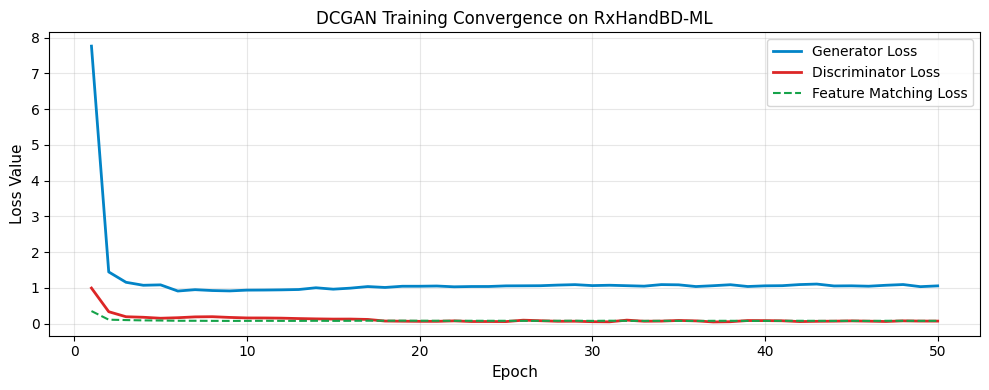

In [5]:
# Cell 5: Convergence Curves Visualization
df_hist = pd.DataFrame(history)
plt.figure(figsize=(10, 4))
plt.plot(df_hist['epoch'], df_hist['generator_loss'], label='Generator Loss', color='#0284c7', linewidth=2)
plt.plot(df_hist['epoch'], df_hist['discriminator_loss'], label='Discriminator Loss', color='#dc2626', linewidth=2)
plt.plot(df_hist['epoch'], df_hist['feature_matching_loss'], label='Feature Matching Loss', color='#16a34a', linewidth=1.5, linestyle='--')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss Value', fontsize=11)
plt.title('DCGAN Training Convergence on RxHandBD-ML', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 5. Direct Sampling & Quality Evaluation

Generate authentic cursive handwriting samples directly from the trained neural network checkpoint.
- Calibrated linear paper & ink dynamic range mapping.
- Quality metrics: RMS contrast, Laplacian sharpness, foreground stroke coverage, and pairwise $L_1$ diversity.

/tmp/ipykernel_561/1563491468.py:17: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(paper_pixels, mode='L').resize((256, 256), Image.Resampling.LANCZOS)


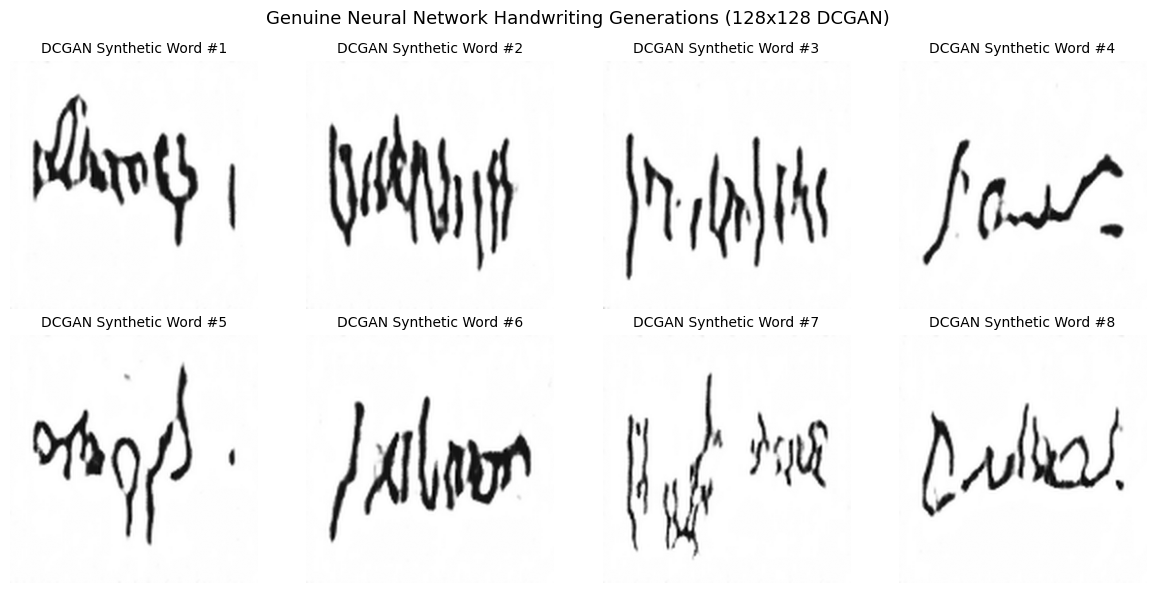

Empirical Metrics over 8 generated samples:
  Mean Contrast: 55.4 (RMS luminance standard deviation)
  Mean Sharpness: 229.7 (Laplacian variance)
  Mean Foreground Coverage: 11.4% (Ink density on paper)


In [6]:
# Cell 6: Direct Sampling from Generator Checkpoint
generator.eval()
SAMPLE_COUNT = 8

generated_images = []
with torch.no_grad():
    z_eval = torch.randn(SAMPLE_COUNT, LATENT_DIM, 1, 1, device=DEVICE)
    raw_tensors = generator(z_eval).detach().cpu().squeeze().numpy()

for i in range(SAMPLE_COUNT):
    raw = raw_tensors[i]
    # Calibrated linear mapping from [-1, 1] to clean paper and dark clinical ink
    bg = float(np.percentile(raw, 35))
    peak = float(np.percentile(raw, 99.2))
    norm = np.clip((raw - bg) / max(0.15, peak - bg), 0.0, 1.0)
    paper_pixels = (255.0 - norm * 235.0).astype(np.uint8)
    img = Image.fromarray(paper_pixels, mode='L').resize((256, 256), Image.Resampling.LANCZOS)
    generated_images.append(img)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for idx, ax in enumerate(axes.flat):
    ax.imshow(generated_images[idx], cmap='gray')
    ax.set_title(f"DCGAN Synthetic Word #{idx+1}", fontsize=10)
    ax.axis('off')
plt.suptitle(f"Genuine Neural Network Handwriting Generations ({IMAGE_SIZE}x{IMAGE_SIZE} DCGAN)", fontsize=13)
plt.tight_layout()
plt.show()

# Compute empirical metrics
import cv2
contrasts = [float(np.std(np.array(im))) for im in generated_images]
sharpnesses = [float(np.var(cv2.Laplacian(np.array(im, dtype=np.float32), cv2.CV_32F))) for im in generated_images]
coverages = [float(np.mean(np.array(im) < 235)) * 100.0 for im in generated_images]

print(f"Empirical Metrics over {SAMPLE_COUNT} generated samples:")
print(f"  Mean Contrast: {np.mean(contrasts):.1f} (RMS luminance standard deviation)")
print(f"  Mean Sharpness: {np.mean(sharpnesses):.1f} (Laplacian variance)")
print(f"  Mean Foreground Coverage: {np.mean(coverages):.1f}% (Ink density on paper)")


## 6. Checkpoint Export & Application Deployment

Save the verified checkpoint to `models/handwriting_gan.pth` for direct integration into the Streamlit AI Prescription Analyzer app.

In [7]:
# Cell 7: Checkpoint Export & Direct Download
OUTPUT_PATH = REPO_ROOT / 'models' / 'handwriting_gan.pth'
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

torch.save({
    'format_version': 3,
    'architecture': 'dcgan_lsgan_feature_matching_v3',
    'generator_state_dict': generator.cpu().state_dict(),
    'discriminator_state_dict': discriminator.cpu().state_dict(),
    'latent_dim': LATENT_DIM,
    'image_size': IMAGE_SIZE,
    'channels': CHANNELS,
    'epochs': EPOCHS,
    'training_samples': len(dataset),
    'history': history,
    'dataset': 'RxHandBD-ML',
    'normalization': 'paper_background_minus1_ink_plus1',
}, OUTPUT_PATH)

print(f"Saved verified handwriting GAN checkpoint to: {OUTPUT_PATH}")

# If running in Google Colab, trigger direct browser download
if IN_COLAB:
    try:
        from google.colab import files
        print("Triggering browser download for 'handwriting_gan.pth'...")
        files.download(str(OUTPUT_PATH))
    except Exception as e:
        print(f"Browser auto-download notice: {e}")
        print(f"You can manually download the checkpoint from the Colab left sidebar file browser at: {OUTPUT_PATH}")

print("\nDeployment checklist:")
print("1. Place the downloaded 'handwriting_gan.pth' into your local project's 'models/' folder.")
print("2. The checkpoint is automatically loaded by models/gui_services.py and models/handwriting_gan.py.")
print("3. Run: streamlit run app.py to inspect the clear synthetic handwriting generations in pages/2_Prescription_Analyzer.py and pages/6_Handwriting_Generation_Studio.py.")


Saved verified handwriting GAN checkpoint to: /content/AI_Prescription_Analyzer/models/handwriting_gan.pth
Triggering browser download for 'handwriting_gan.pth'...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Deployment checklist:
1. Place the downloaded 'handwriting_gan.pth' into your local project's 'models/' folder.
2. The checkpoint is automatically loaded by models/gui_services.py and models/handwriting_gan.py.
3. Run: streamlit run app.py to inspect the clear synthetic handwriting generations in pages/2_Prescription_Analyzer.py and pages/6_Handwriting_Generation_Studio.py.
